# Curvilinear grids

This notebook is a user guide to `CurvilinearGrid`, Devito's structured grid
for domains with a curved boundary. It covers, each with a short runnable
example:

1. what a curvilinear grid is and when to use one;
2. the map from computational to physical space, `TerrainFollowing` and custom
   maps;
3. the attributes of the grid: Dimensions, spacing, coordinates, metrics,
   Jacobian and smallest cell size;
4. physical and computational derivatives, second, mixed, nested, staggered
   and rotated derivatives, and the `space_order` of the grid;
5. transposes and adjoint tests;
6. sources and receivers, in physical coordinates;
7. resampling a model from a Cartesian grid, and the transpose;
8. the free surface;
9. a complete example, the acoustic wave equation under a tilted free surface
   compared with the analytic solution;
10. MPI and the current limits.

## 1. What a curvilinear grid is

A `Grid` discretizes a box with uniformly spaced nodes. When the boundary of
the domain is not a plane, e.g. the topography of a seismic survey, a box
grid cuts it in a staircase, and the error of the staircase dominates a
simulation with a free surface.

A `CurvilinearGrid` keeps the logically Cartesian grid of a `Grid`, the
*computational* grid, with coordinates $\xi$ (and $\eta$ for the vertical
axis), and places its nodes in *physical* space with a smooth map
$\mathbf{x}(\boldsymbol{\xi})$, so that the curved boundary is a grid line.
Everything that is about indices is unchanged: loops, halos, MPI domain
decomposition, SubDomains. Everything that is about physics is in physical
space: derivatives `u.dx`, `u.laplace`, `grad`, `div` are w.r.t. the physical
coordinates, and sources and receivers are placed at physical positions.

Use one when the geometry of a boundary matters, a free surface over
topography being the typical case. The code using the grid does not change:
swap `Grid` for `CurvilinearGrid`.

## 2. The map

### `TerrainFollowing`

`TerrainFollowing(surface, depth)` is a vertical map: the lateral coordinates
are unchanged, and each column is stretched linearly between the surface
$s(x)$ and a flat bottom at $z = \mathrm{depth}$,

$$
z(x, \eta) = s(x) + (\eta - o_z)\,\frac{\mathrm{depth} - s(x)}{l_z},
$$

with $o_z$ and $l_z$ the origin and extent of the vertical axis of the
computational grid. As for a `Grid`, the vertical axis is the last one and
points down:

* `surface` is the *depth* of the surface, positive down. A topography given
  as an *elevation* above a datum, positive up, is passed as
  `surface=-elevation`;
* the first row of the grid is the surface, the last row the bottom;
* `surface` is either a callable of the lateral coordinates, `s(x)` in 2D and
  `s(x, y)` in 3D, or an array with one value per lateral grid node;
* `depth` defaults to the bottom of the computational grid, $o_z + l_z$, and
  a flat surface at $s = o_z$ is then the identity map.

Here a hill 120 m high, given as an elevation:

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from devito import (CurvilinearGrid, CurvilinearMap, Eq, Function, Grid, Operator,
                    SparseFunction, SparseTimeFunction, TerrainFollowing,
                    TimeFunction)

x_nodes = np.linspace(0., 2000., 101)
elevation = 120.*np.exp(-((x_nodes - 1000.)/300.)**2)

hill = CurvilinearGrid(shape=(101, 51), extent=(2000., 1000.),
                       mapping=TerrainFollowing(surface=-elevation, depth=1000.))

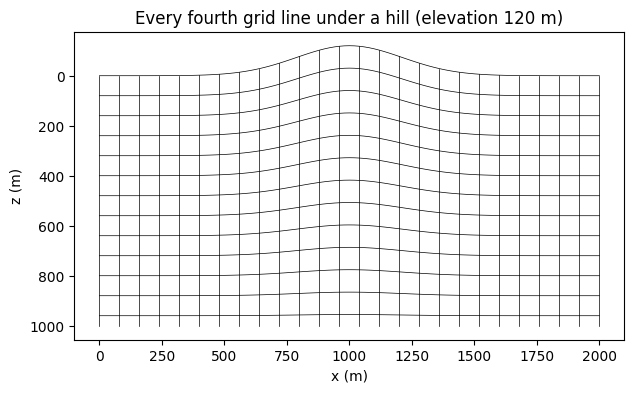

In [2]:
# NBVAL_IGNORE_OUTPUT
def plot_grid_lines(grid, step, ax):
    # Lines of constant lateral index, then lines of constant eta
    x_coord, z_coord = (c.data for c in grid.coordinates)
    ax.plot(x_coord[::step, :].T, z_coord[::step, :].T, 'k', lw=.5)
    ax.plot(x_coord[:, ::step], z_coord[:, ::step], 'k', lw=.5)
    ax.invert_yaxis()
    ax.set_aspect('equal')
    ax.set_xlabel('x (m)')
    ax.set_ylabel('z (m)')


fig, ax = plt.subplots(figsize=(10, 4))
plot_grid_lines(hill, 4, ax)
ax.set_title('Every fourth grid line under a hill (elevation 120 m)')
plt.show()

### Custom maps

A map is a subclass of `CurvilinearMap`. It must provide

* `forward(grid, computational)`: the physical coordinates of computational
  points, one array per axis. It must be smooth and defined past the domain
  too: the halo nodes, which the stencils read, take their positions from it;
* `inverse(grid, points)`: the computational coordinates of physical points,
  an array of shape `(npoint, ndim)`, needed to place sources and receivers
  and by the free surface.

The metric terms, their derivatives and the Jacobian are then computed by
finite differences of `forward` at the space order of the grid. A map with
closed forms can override `metrics`, `metric_derivatives` and `jacobian`, as
`TerrainFollowing` does, and `validate(grid)` to check its parameters.

A sheared grid, every column shifted down by `slope*x`:

In [3]:
class Shear(CurvilinearMap):
    # z = eta + slope*x, x = xi

    def __init__(self, slope):
        self.slope = slope

    def forward(self, grid, computational):
        xi, eta = computational
        return xi, eta + self.slope*xi

    def inverse(self, grid, points):
        return np.stack([points[:, 0], points[:, 1] - self.slope*points[:, 0]],
                        axis=1)


sheared = CurvilinearGrid(shape=(21, 21), extent=(200., 200.), mapping=Shear(.2))
x, y = sheared.dimensions
# d eta / d x = -slope, from finite differences of `forward`
print(f'eta_x = {float(sheared.metrics[(x, y)].data.mean()):.3f}')

eta_x = -0.200


## 3. What the grid provides

* `grid.dimensions`, `grid.shape`, `grid.spacing`, `grid.extent` and
  `grid.origin` describe the *computational* grid, as for a `Grid`. In 2D the
  Dimensions are `x` and `y`, `y` being the vertical axis, and in 3D `x`,
  `y`, `z`.
* `grid.coordinates`: the physical coordinates of the nodes, one `Function`
  per axis, halo included.
* `grid.metrics`: the metric terms $\partial\xi_j/\partial x_i$, keyed by
  (physical Dimension, computational Dimension). An entry is a `Function`,
  named after the computational coordinate ($\xi$, $\eta$, $\zeta$) and the
  physical axis, e.g. `eta_x` for $\partial\eta/\partial x$, or a number when
  it is constant by construction of the map.
* `grid.metric_derivatives`: the second derivatives
  $\partial^2\xi_j/\partial x_i^2$, used by second derivatives.
* `grid.jacobian`: $J = \det(\partial\mathbf{x}/\partial\boldsymbol{\xi})$,
  the ratio of a physical to a computational cell area.
* `grid.min_spacing`: the smallest physical distance between neighbouring
  nodes, to set a stable time step.

These are built from the map the first time they are needed.

In [4]:
x, y = hill.dimensions
print(f'Computational shape {hill.shape}, spacing {float(hill.spacing[0])} m')
print(f'Smallest physical cell size {hill.min_spacing:.2f} m')
hill.metrics

Computational shape (101, 51), spacing 20.0 m
Smallest physical cell size 20.00 m


{(x, x): 1, (y, x): 0, (x, y): eta_x(x, y), (y, y): eta_y(x, y)}

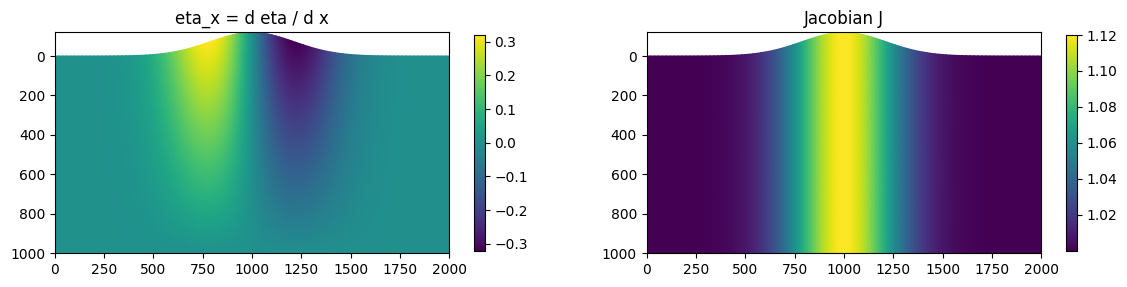

In [5]:
# NBVAL_IGNORE_OUTPUT
x_coord, z_coord = (c.data for c in hill.coordinates)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, function, title in zip(axes, [hill.metrics[(x, y)], hill.jacobian],
                               ['eta_x = d eta / d x', 'Jacobian J'], strict=True):
    image = ax.pcolormesh(x_coord, z_coord, function.data, shading='gouraud')
    ax.invert_yaxis()
    ax.set_aspect('equal')
    ax.set_title(title)
    fig.colorbar(image, ax=ax, shrink=.7)
plt.show()

## 4. Derivatives

### Physical and computational derivatives

On a curvilinear grid `u.dx` is the derivative w.r.t. the physical coordinate
$x$. It is evaluated by the chain rule over the computational derivatives,

$$
\frac{\partial u}{\partial x} = \frac{\partial \xi}{\partial x}
\frac{\partial u}{\partial \xi} + \frac{\partial \eta}{\partial x}
\frac{\partial u}{\partial \eta},
$$

each metric term multiplying the computational derivative at the point where
it is evaluated. The derivative w.r.t. the computational coordinate itself is
`u.dx(computational=True)`, which ignores the map.

In [6]:
u = Function(name='u', grid=hill, space_order=2)
u.dx.evaluate

-u(x, y)/h_x + u(x + h_x, y)/h_x + (-0.5*u(x, y - h_y)/h_y + 0.5*u(x, y + h_y)/h_y)*eta_x(x, y)

In [7]:
u.dx(computational=True).evaluate

-u(x, y)/h_x + u(x + h_x, y)/h_x

A check: the physical depth $z$, stored in `grid.coordinates`, has physical
derivatives $\partial z/\partial x = 0$ and $\partial z/\partial z = 1$,
while its computational derivative along $x$ is the slope of the grid lines.

In [8]:
# NBVAL_IGNORE_OUTPUT
depth_field = Function(name='depth_field', grid=hill, space_order=8)
dzdx = Function(name='dzdx', grid=hill, space_order=8)
dzdz = Function(name='dzdz', grid=hill, space_order=8)
dzdxi = Function(name='dzdxi', grid=hill, space_order=8)
depth_field.data_with_halo[:] = hill.coordinates[1].data_with_halo

Operator([Eq(dzdx, depth_field.dx), Eq(dzdz, depth_field.dy),
          Eq(dzdxi, depth_field.dx(computational=True))]).apply()

NUMA domain count autodetection failed, assuming 1


Operator `Kernel` ran in 0.01 s


PerformanceSummary([(PerfKey(name='section0', rank=None),
                     PerfEntry(time=7.7e-05, gflopss=0.0, gpointss=0.0, oi=0.0, ops=0, itershapes=[]))])

In [9]:
interior = (slice(4, -4), slice(4, -4))
assert np.abs(dzdx.data[interior]).max() < 1e-4
assert np.abs(dzdz.data[interior] - 1).max() < 1e-4
print(f'largest grid-line slope dz/dxi: {np.abs(dzdxi.data).max():.3f}')

largest grid-line slope dz/dxi: 0.343


### Second, mixed and nested derivatives

A second derivative is not two first derivatives: it is expanded with the
products of metrics, the cross computational derivative and the metric
derivatives,

$$
\frac{\partial^2 u}{\partial x^2} = \sum_{jk}
\frac{\partial\xi_j}{\partial x}\frac{\partial\xi_k}{\partial x}
\frac{\partial^2 u}{\partial\xi_j\partial\xi_k} + \sum_j
\frac{\partial^2\xi_j}{\partial x^2}\frac{\partial u}{\partial\xi_j},
$$

so that over a flat surface `u.dx2` and `u.laplace` are exactly the stencils
of a `Grid`. Mixed derivatives such as `u.dxdy`, and higher ones, nest first
and second derivatives. Nested expressions such as `(b*u.dx).dx` or
`div(b*grad(u))` are written as on a `Grid`.

The metric Functions have a halo of `space_order` points (8 by default, the
`space_order` argument of `CurvilinearGrid`), which bounds the reach of the
stencils: up to two nested derivatives of Functions of space order at most
the grid's are supported. A derivative of a higher order raises an error
asking for a larger grid `space_order`.

In [10]:
high_order = Function(name='high_order', grid=hill, space_order=12)
try:
    _ = high_order.dx.evaluate
except ValueError as error:
    print(error)

Derivative(high_order(x, y), x) has fd_order=12 along x, larger than the space_order=8 of its CurvilinearGrid metrics; increase CurvilinearGrid(space_order=...)


### Staggered and rotated derivatives

A derivative evaluated at a staggered point, `u.dx(x0=x + x.spacing/2)`, and
a rotated staggered derivative, `u.dx(method='RSFD', x0=...)`, follow the
same chain rule, the metric terms being interpolated to the evaluation point
at the grid order.

In [11]:
u.dy(x0=y + y.spacing/2).evaluate

(-u(x, y)/h_y + u(x, y + h_y)/h_y)*(0.598144531*eta_y(x, y) - 0.00244140625*eta_y(x, y - 3*h_y) + 0.0239257813*eta_y(x, y - 2*h_y) - 0.119628906*eta_y(x, y - h_y) + 0.598144531*eta_y(x, y + h_y) - 0.119628906*eta_y(x, y + 2*h_y) + 0.0239257813*eta_y(x, y + 3*h_y) - 0.00244140625*eta_y(x, y + 4*h_y))

## 5. Transposes and adjoint tests

The transpose `.T` of a physical derivative is its exact discrete transpose:
each term $c\,D$ of the chain rule becomes $D^T(c\,\cdot)$, the metric inside
the transposed computational derivative. A dot test
$\langle D f, g\rangle = \langle f, D^T g\rangle$:

In [12]:
# NBVAL_IGNORE_OUTPUT
rng = np.random.default_rng(0)
f = Function(name='f', grid=hill, space_order=8)
g = Function(name='g', grid=hill, space_order=8)
b = Function(name='b', grid=hill, space_order=8)
f_out = Function(name='f_out', grid=hill, space_order=8)
g_out = Function(name='g_out', grid=hill, space_order=8)
f.data[:] = rng.standard_normal(hill.shape)
g.data[:] = rng.standard_normal(hill.shape)
b.data[:] = 1 + rng.random(hill.shape)

Operator([Eq(f_out, (b*f.dx).dx), Eq(g_out, (b*g.dx.T).dx.T)]).apply()

Operator `Kernel` ran in 0.01 s


PerformanceSummary([(PerfKey(name='section0', rank=None),
                     PerfEntry(time=5.8e-05, gflopss=0.0, gpointss=0.0, oi=0.0, ops=0, itershapes=[])),
                    (PerfKey(name='section1', rank=None),
                     PerfEntry(time=4.4e-05, gflopss=0.0, gpointss=0.0, oi=0.0, ops=0, itershapes=[]))])

In [13]:
forward = np.dot(f_out.data.ravel(), g.data.ravel())
backward = np.dot(f.data.ravel(), g_out.data.ravel())
assert np.isclose(forward, backward, rtol=1e-5)

## 6. Sources and receivers

The coordinates of a `SparseFunction` on a curvilinear grid are physical. They
are mapped to the computational grid with the inverse map every time an
`Operator` runs, so they can be changed between runs, and interpolation is
then done in the computational grid as on a `Grid`.

Injection divides by the Jacobian at the grid points of the field (interpolated
there for a staggered field), so that a source is a Dirac in physical space:
a unit source integrates to one computational cell area,
$\sum J\,v\,h_\xi h_\eta = h_\xi h_\eta$, as on a `Grid`. Injection is then the
transpose of interpolation in the inner product weighted by the Jacobian,

$$
\langle P u, d\rangle = \sum J\, u\, (P^T d).
$$

In [14]:
# NBVAL_IGNORE_OUTPUT
points = np.array([[600., 300.], [1000., -200.], [1400., 500.]])
rec = SparseFunction(name='rec', grid=hill, npoint=3, coordinates=points)
src = SparseFunction(name='src', grid=hill, npoint=3, coordinates=points)
u = Function(name='u', grid=hill, space_order=4)
v = Function(name='v', grid=hill, space_order=4)
u.data[:] = rng.standard_normal(hill.shape)
src.data[:] = rng.standard_normal(3)

Operator([rec.interpolate(u), src.inject(v, src)]).apply()

Operator `Kernel` ran in 0.01 s


PerformanceSummary([(PerfKey(name='section0', rank=None),
                     PerfEntry(time=2.8e-05, gflopss=0.0, gpointss=0.0, oi=0.0, ops=0, itershapes=[])),
                    (PerfKey(name='section1', rank=None),
                     PerfEntry(time=2.7e-05, gflopss=0.0, gpointss=0.0, oi=0.0, ops=0, itershapes=[]))])

In [15]:
forward = np.dot(rec.data, src.data)
backward = np.sum(hill.jacobian.data*u.data*v.data)
assert np.isclose(forward, backward, rtol=1e-5)
# The point at x = 1 km, z = -200 m is 80 m above the top of the hill: its
# computational depth is negative, outside the grid, and it records nothing
print(hill.to_computational(points).round(1))

[[ 600.   313.9]
 [1000.   -71.4]
 [1400.   509.9]]


`grid.to_computational(points)` and `grid.to_physical(points)` apply the map
to arrays of points. `SparseFunction.guard` restricts an expression to the
points inside the grid, i.e. between the surface and the bottom.

## 7. Resampling a Cartesian model

Models usually come on a Cartesian grid. `grid.resample(f, cartesian)` sets a
`Function` `f` on the curvilinear grid to a Cartesian `Function` interpolated
at the physical nodes: multilinear in the Cartesian grid, i.e. a 1D
interpolation along each column for a vertical map. Nodes above or below the
Cartesian model take the value of its nearest node.
`grid.resample(f, cartesian, transpose=True)` applies the exact transpose,
e.g. to bring a gradient computed on the curvilinear grid back to the
Cartesian one. Both work across different domain decompositions.

In [16]:
cartesian_grid = Grid(shape=(101, 61), extent=(2000., 1200.), origin=(0., -200.))
cartesian_velocity = Function(name='cartesian_velocity', grid=cartesian_grid)
z_cartesian = np.linspace(-200., 1000., 61)
cartesian_velocity.data[:] = np.where(z_cartesian < 400., 1500., 2500.)

velocity = Function(name='velocity', grid=hill)
hill.resample(velocity, cartesian_velocity)

# The transpose, checked by a dot test
transposed = Function(name='transposed', grid=cartesian_grid)
weights = Function(name='weights', grid=hill)
weights.data[:] = rng.standard_normal(hill.shape)
hill.resample(weights, transposed, transpose=True)
assert np.isclose(np.sum(velocity.data*weights.data),
                  np.sum(cartesian_velocity.data*transposed.data), rtol=1e-5)

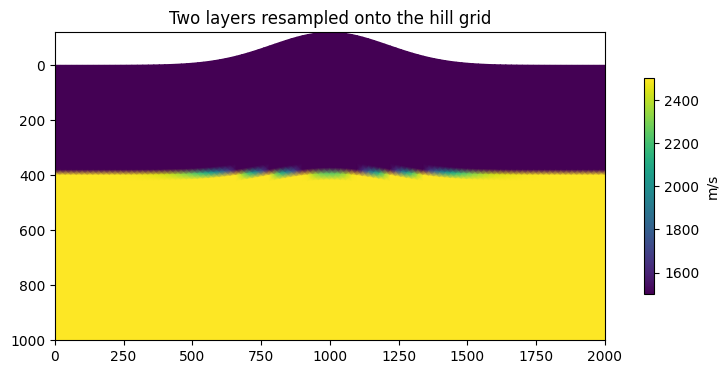

In [17]:
# NBVAL_IGNORE_OUTPUT
fig, ax = plt.subplots(figsize=(10, 4))
image = ax.pcolormesh(*(c.data for c in hill.coordinates), velocity.data,
                      shading='gouraud', cmap='viridis')
ax.invert_yaxis()
ax.set_aspect('equal')
ax.set_title('Two layers resampled onto the hill grid')
fig.colorbar(image, ax=ax, shrink=.7, label='m/s')
plt.show()

## 8. The free surface

A free surface, $u = 0$ on the surface, is the first row of the grid.
`grid.free_surface(u.forward)` returns the equations imposing it, to follow
the update of `u`: they set the surface row to zero and every ghost node
above it, in the halo, to minus the field at its *image* through the closest
point of the surface, interpolated at the space order of `u` from the nodes at
or below the surface.

Over a plane the image is exact: the solution of the free-surface problem is
odd w.r.t. the plane, so the ghost rows are the exact continuation of the
field, to the interpolation order. Over a flat surface it is the usual odd
mirror $u(-k) = -u(k)$. The mirror along the grid columns,
`u[t+1, x, -k] = -u[t+1, x, k]`, is only second order over a tilted surface,
since the columns are not normal to it. Over a curved surface the image is
taken through the tangent plane at the closest point.

`rows` (half the space order of `u` by default) sets the number of ghost rows
and `order` the number of interpolation points.

## 9. Example: acoustic waves under a tilted free surface

A plane dipping at 0.1, from $z = 0$ at the left of a 3 km line to
$z = 300$ m at the right, over a homogeneous medium at 1500 m/s. The wave
equation is written as on a `Grid`, and the time step is set from
`grid.min_spacing`.

In [18]:
slope, velocity_value = .1, 1500.
grid = CurvilinearGrid(shape=(301, 151), extent=(3000., 1500.),
                       mapping=TerrainFollowing(surface=lambda x: slope*x,
                                                depth=1500.))
x, y = grid.dimensions
f0, t0, tn = 10., .12, 1.2
dt = .1*grid.min_spacing/velocity_value
nt = int(np.ceil(tn/dt)) + 1
time_values = np.arange(nt)*dt


def ricker(t):
    a = (np.pi*f0*(t - t0))**2
    return (1 - 2*a)*np.exp(-a)


m = Function(name='m', grid=grid, space_order=8)
m.data[:] = 1/velocity_value**2

The source is 200 m (computational) below the surface at $x = 1.5$ km, and
101 receivers 100 m below it. They are placed at grid nodes, with
`grid.to_physical`, so that the comparison below measures the propagation and
the free surface rather than the interpolation of the sources and receivers.

In [19]:
source_position = grid.to_physical([[1500., 200.]])
receiver_positions = grid.to_physical(np.stack([np.linspace(1000., 2000., 101),
                                                np.full(101, 100.)], axis=1))
src = SparseTimeFunction(name='src', grid=grid, npoint=1, nt=nt,
                         coordinates=source_position)
src.data[:, 0] = ricker(time_values)


def simulate(surface_equations, u, rec):
    update = Eq(u.forward, 2*u - u.backward + dt**2*u.laplace/m)
    op = Operator([update] + surface_equations +
                  src.inject(field=u.forward, expr=src*dt**2/m) +
                  rec.interpolate(expr=u))
    return op


u = TimeFunction(name='u', grid=grid, space_order=8, time_order=2)
rec = SparseTimeFunction(name='rec', grid=grid, npoint=101, nt=nt,
                         coordinates=receiver_positions)
op = simulate(grid.free_surface(u.forward), u, rec)

In [20]:
# NBVAL_IGNORE_OUTPUT
snapshot_step = int(.55/dt)
op.apply(dt=dt, time_M=snapshot_step)
snapshot = u.data[(snapshot_step + 1) % 3].copy()
op.apply(dt=dt, time_m=snapshot_step + 1, time_M=nt - 2)

Operator `Kernel` ran in 0.14 s


Operator `Kernel` ran in 0.17 s


PerformanceSummary([(PerfKey(name='section0', rank=None),
                     PerfEntry(time=0.12949900000000023, gflopss=0.0, gpointss=0.0, oi=0.0, ops=0, itershapes=[])),
                    (PerfKey(name='section1', rank=None),
                     PerfEntry(time=0.015461000000000029, gflopss=0.0, gpointss=0.0, oi=0.0, ops=0, itershapes=[])),
                    (PerfKey(name='section2', rank=None),
                     PerfEntry(time=0.01701600000000005, gflopss=0.0, gpointss=0.0, oi=0.0, ops=0, itershapes=[]))])

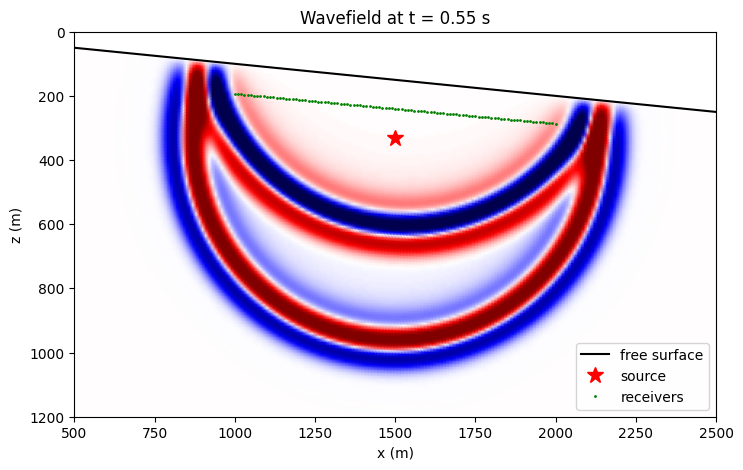

In [21]:
# NBVAL_IGNORE_OUTPUT
fig, ax = plt.subplots(figsize=(10, 5))
clip = np.abs(snapshot).max()/2
x_coord, z_coord = (c.data for c in grid.coordinates)
ax.pcolormesh(x_coord, z_coord, snapshot, cmap='seismic', vmin=-clip, vmax=clip,
              shading='gouraud')
ax.plot(x_coord[:, 0], z_coord[:, 0], 'k', lw=1.5, label='free surface')
ax.plot(*source_position.T, 'r*', ms=12, label='source')
ax.plot(*receiver_positions.T, 'g.', ms=2, label='receivers')
ax.set_xlim(500., 2500.)
ax.set_ylim(1200., 0.)
ax.set_aspect('equal')
ax.set_xlabel('x (m)')
ax.set_ylabel('z (m)')
ax.set_title(f'Wavefield at t = {(snapshot_step + 1)*dt:.2f} s')
ax.legend(loc='lower right')
plt.show()

### Comparison with the image-source solution

The solution under a planar free surface is the free-space field of the source
minus that of its mirror image across the plane. For
$m\,u_{tt} - \Delta u = A\,s(t)\,\delta(\mathbf{x}-\mathbf{x}_s)$ in 2D, the
free-space field at distance $r$ is

$$
u(r, t) = \frac{A}{2\pi}\int_0^{\cosh^{-1}(t/\tau_0)}
s(t - \tau_0\cosh\theta)\,d\theta, \qquad \tau_0 = r/c,
$$

and the injection of `src` with weight `dt**2/m` is a source of amplitude
$A = h_\xi h_\eta$, the computational cell area. We also run the same
simulation with the mirror along the grid columns.

In [22]:
def free_space(r, t, amplitude, c=velocity_value):
    field = np.zeros((len(t), len(r)))
    unit = np.linspace(0, 1, 801)
    for j, tau0 in enumerate(r/c):
        valid = t > tau0
        theta = np.arccosh(t[valid]/tau0)[:, None]*unit[None, :]
        field[valid, j] = np.trapezoid(ricker(t[valid, None] - tau0*np.cosh(theta)),
                                       theta, axis=1)
    return amplitude*field/(2*np.pi)


normal = np.array([slope, -1.])
image_position = source_position[0] - \
    2*(normal @ source_position[0])/(normal @ normal)*normal
amplitude = np.prod(np.array(grid.spacing, dtype=np.float64))
analytic = (
    free_space(np.linalg.norm(receiver_positions - source_position, axis=1),
               time_values, amplitude) -
    free_space(np.linalg.norm(receiver_positions - image_position, axis=1),
               time_values, amplitude)
)

In [23]:
# NBVAL_IGNORE_OUTPUT
t = grid.stepping_dim
u_column = TimeFunction(name='u_column', grid=grid, space_order=8, time_order=2)
rec_column = SparseTimeFunction(name='rec_column', grid=grid, npoint=101, nt=nt,
                                coordinates=receiver_positions)
column_mirror = [Eq(u_column[t+1, x, 0], 0)]
column_mirror += [Eq(u_column[t+1, x, -k], -u_column[t+1, x, k]) for k in range(1, 5)]
simulate(column_mirror, u_column, rec_column).apply(dt=dt, time_M=nt - 2)

Writing to the HALO along potentially distributed Dimensions; set their Grid topology entries to 1


Writing to the HALO along potentially distributed Dimensions; set their Grid topology entries to 1


Writing to the HALO along potentially distributed Dimensions; set their Grid topology entries to 1


Writing to the HALO along potentially distributed Dimensions; set their Grid topology entries to 1


Operator `Kernel` ran in 0.24 s


PerformanceSummary([(PerfKey(name='section0', rank=None),
                     PerfEntry(time=0.16266000000000128, gflopss=0.0, gpointss=0.0, oi=0.0, ops=0, itershapes=[])),
                    (PerfKey(name='section1', rank=None),
                     PerfEntry(time=0.033894000000000084, gflopss=0.0, gpointss=0.0, oi=0.0, ops=0, itershapes=[])),
                    (PerfKey(name='section2', rank=None),
                     PerfEntry(time=0.040516000000000094, gflopss=0.0, gpointss=0.0, oi=0.0, ops=0, itershapes=[]))])

In [24]:
# NBVAL_IGNORE_OUTPUT
misfit = np.linalg.norm(rec.data - analytic)/np.linalg.norm(analytic)
misfit_column = np.linalg.norm(rec_column.data - analytic)/np.linalg.norm(analytic)
print(f'Relative L2 misfit, image mirror (grid.free_surface): {misfit:.5f}')
print(f'Relative L2 misfit, mirror along the columns:        {misfit_column:.5f}')

Relative L2 misfit, image mirror (grid.free_surface): 0.00093
Relative L2 misfit, mirror along the columns:        0.00163


In [25]:
assert misfit < 2e-3
assert misfit_column > misfit

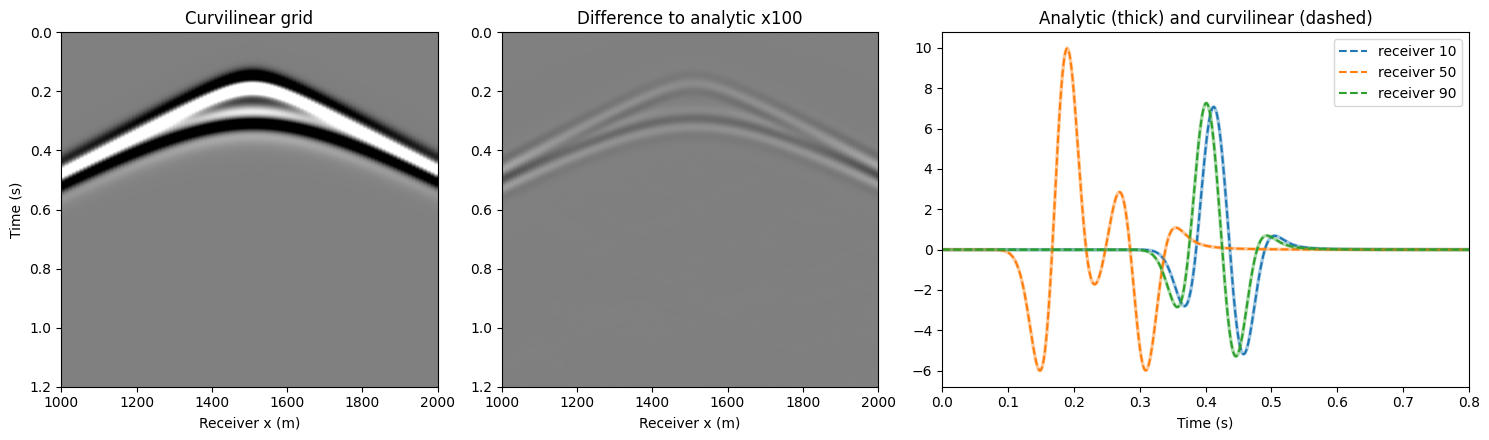

In [26]:
# NBVAL_IGNORE_OUTPUT
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5),
                         gridspec_kw={'width_ratios': [1, 1, 1.4]})
extent = [1000., 2000., time_values[-1], 0]
clip = np.abs(analytic).max()/3
panels = [rec.data, 100*(rec.data - analytic)]
titles = ['Curvilinear grid', 'Difference to analytic x100']
for ax, data, title in zip(axes[:2], panels, titles, strict=True):
    ax.imshow(data, aspect='auto', cmap='gray', vmin=-clip, vmax=clip, extent=extent)
    ax.set_xlabel('Receiver x (m)')
    ax.set_title(title)
axes[0].set_ylabel('Time (s)')
for j, color in zip([10, 50, 90], ['C0', 'C1', 'C2'], strict=True):
    axes[2].plot(time_values, analytic[:, j], color=color, lw=2.5, alpha=.4)
    axes[2].plot(time_values, rec.data[:, j], '--', color=color,
                 label=f'receiver {j}')
axes[2].set_xlim(0, .8)
axes[2].set_xlabel('Time (s)')
axes[2].set_title('Analytic (thick) and curvilinear (dashed)')
axes[2].legend()
plt.tight_layout()
plt.show()

The data match the analytic solution to about $10^{-3}$. At this time step the
remaining misfit is mostly the propagation error, shared with a flat surface;
the image mirror removes the second-order error of the mirror along the
columns, which shows as the larger misfit of the latter. Two choices matter as
much as the boundary for such a comparison: the time step (here a tenth of
the stability limit; second-order time stepping dominates the error at larger
steps), and the position of the source and receivers (linear interpolation
between nodes is second order).

## 10. MPI and limits

### MPI

Everything above runs unchanged under MPI (`DEVITO_MPI=1 mpirun -n 4 ...`).
Each rank builds the coordinate and metric Functions of its own nodes, halo
included, so they need no communication; sparse points are mapped to the
computational grid before being distributed; `resample` works between grids
with any decompositions; and the free-surface equations only run on the ranks
holding the surface.

### Limits

* Derivatives: the halo of the metric Functions, `space_order` of the grid,
  supports two nested derivatives of Functions of space order up to it;
  `method='RSFD'` provides first derivatives only, as on a `Grid`.
* Sparse functions: the default linear interpolation is second order in the
  computational grid; the map's `inverse` is needed, and for a
  `TerrainFollowing` map with an array surface the surface is interpolated
  linearly between nodes.
* Free surface: exact image over a plane; over a curved surface the image is
  taken through the tangent plane at the closest point, and the lateral reach
  of the image stencils must fit in the halo of the field.
* Resampling is multilinear, i.e. second order.